# football-predictor — keşifsel analiz ve sonuçlar

Bu defter `data/` altındaki veriyle çalışır. Önce indir:

```bash
football-predictor download --league T1 --source transfermarkt --seasons 2018-2026
football-predictor download --league T1 --seasons 2026-2027
football-predictor download --league E0 --source transfermarkt --seasons 2018-2026
football-predictor download --league E0 --seasons 2026-2027
```

*Eğitim amaçlıdır, bahis tavsiyesi değildir.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import poisson
from football_predictor.data import load_league, outcome
from football_predictor.model import DixonColes, score_matrix, outcome_probs
from football_predictor.evaluate import evaluate, calibration_table, paired_logloss_diff
pd.set_option("display.precision", 4)
leagues = {lg: load_league(lg, "../data") for lg in ["T1", "E0"]}
for lg, df in leagues.items():
    print(lg, len(df), "maç,", df.Season.nunique(), "sezon:", ", ".join(df.groupby("Season").size().astype(str).radd(df.groupby("Season").size().index + "=")))

T1 2788 maç, 9 sezon: 1819=306, 1920=306, 2021=420, 2122=380, 2223=313, 2324=380, 2425=341, 2526=306, 2627=36
E0 3090 maç, 9 sezon: 1819=380, 1920=380, 2021=380, 2122=380, 2223=380, 2324=380, 2425=380, 2526=380, 2627=50


## 1. Temel oranlar: ev sahibi avantajı ve beraberlikler

In [2]:
rows = []
for lg, df in leagues.items():
    y = outcome(df)
    rows.append({"lig": lg, "maç": len(df), "ev galibiyeti": (y == 0).mean(), "beraberlik": (y == 1).mean(),
                 "deplasman galibiyeti": (y == 2).mean(), "ev gol ort.": df.FTHG.mean(), "deplasman gol ort.": df.FTAG.mean()})
pd.DataFrame(rows).set_index("lig")

,maç,ev galibiyeti,beraberlik,deplasman galibiyeti,ev gol ort.,deplasman gol ort.
lig,,,,,,
T1,2788,0.4473,0.2615,0.2912,1.5775,1.2321
E0,3090,0.4382,0.2317,0.3301,1.5524,1.3058


## 2. Goller Poisson dağılımına uyuyor mu?

Takım farkı yok sayıldığında bile marjinal gol dağılımları Poisson'a yakın olmalı. Asıl soru düşük skorlardaki **bağımlılık**: bağımsız Poisson 0-0 ve 1-1'i az mı tahmin ediyor? Dixon-Coles'un ρ parametresi tam olarak bunu düzeltir.

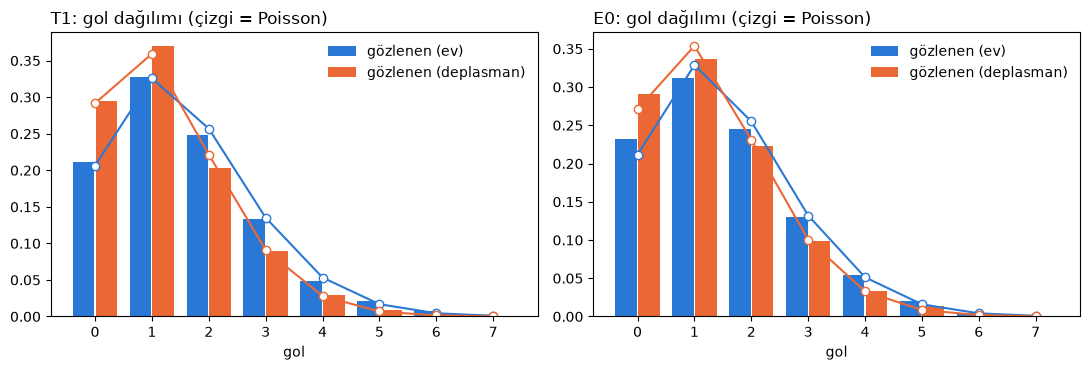

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (lg, df) in zip(axes, leagues.items()):
    g = np.arange(8)
    for col, color, name in [("FTHG", "#2a78d6", "ev"), ("FTAG", "#eb6834", "deplasman")]:
        obs = np.bincount(df[col].clip(upper=7), minlength=8) / len(df)
        ax.bar(g + (-0.2 if col == "FTHG" else 0.2), obs, width=0.38, color=color, label=f"gözlenen ({name})")
        ax.plot(g, poisson.pmf(g, df[col].mean()), "o-", color=color, mfc="white", lw=1.5)
    ax.set_title(f"{lg}: gol dağılımı (çizgi = Poisson)", loc="left"); ax.set_xlabel("gol"); ax.legend(frameon=False)
plt.tight_layout()

In [4]:
rows = []
for lg, df in leagues.items():
    lam, mu = df.FTHG.mean(), df.FTAG.mean()
    m = score_matrix(lam, mu, 0.0, max_goals=10)
    for s in ["0-0", "1-0", "0-1", "1-1"]:
        i, j = map(int, s.split("-"))
        obs = ((df.FTHG == i) & (df.FTAG == j)).mean()
        rows.append({"lig": lg, "skor": s, "gözlenen": obs, "bağımsız Poisson": m[i, j], "oran": obs / m[i, j]})
pd.DataFrame(rows)

,lig,skor,gözlenen,bağımsız Poisson,oran
0,T1,0-0,0.0710,0.0602,1.1791
1,T1,1-0,0.0886,0.0950,0.9324
2,T1,0-1,0.0689,0.0742,0.9280
3,T1,1-1,0.1298,0.1171,1.1091
4,E0,0-0,0.0573,0.0574,0.9985
5,E0,1-0,0.0822,0.0891,0.9230
6,E0,0-1,0.0715,0.0749,0.9547
7,E0,1-1,0.1087,0.1163,0.9350


Not: Bu basit karşılaştırma takım güç farklarını yok sayar; gerçek ρ tahmini, takım parametreleriyle birlikte yapılan maksimum olabilirlik tahminidir (aşağıda).

## 3. Model parametreleri (tüm veri, seçilen ξ)

In [5]:
models = {}
for lg, df in leagues.items():
    m = DixonColes.load(f"../models/{lg}.json")
    models[lg] = m
    print(f"{lg}: xi={m.xi}, ev avantajı γ={m.home:.3f} (×{np.exp(m.home):.2f}), rho={m.rho:.3f}, maç={m.n_matches}")
models["E0"].ratings().head(10)

T1: xi=0.003, ev avantajı γ=0.242 (×1.27), rho=-0.084, maç=2788
E0: xi=0.003, ev avantajı γ=0.142 (×1.15), rho=-0.102, maç=3090


,team,attack,defence,strength
0,Arsenal,0.2227,-0.3172,0.5399
1,Manchester City,0.3906,-0.0996,0.4901
2,Brighton & Hove Albion,0.2775,0.0478,0.2297
3,Liverpool,0.2396,0.0359,0.2037
4,Manchester United,0.2558,0.1258,0.1300
5,Hull City,-0.0751,-0.1502,0.0751
6,Bournemouth,0.1567,0.1954,-0.0387
7,Chelsea,0.1796,0.2323,-0.0527
8,Brentford,0.1331,0.1859,-0.0527
9,Leeds United,0.0205,0.1021,-0.0816


## 4. Değerlendirme (zaman sıralı, haftalık yeniden eğitim)

Her test maçı, yalnızca o haftanın pazartesisinden **önceki** maçlarla eğitilmiş bir modelle tahmin edilir. ξ, test sezonundan önceki doğrulama sezonunda seçilir.

In [6]:
from football_predictor.values import SquadValues, league_name_map
def league_values(comp):
    sv = SquadValues.load("../data"); sv.name_to_id = league_name_map("../data", comp); return sv
results = {lg: evaluate(df, values=league_values({"T1": "TR1", "E0": "GB1"}[lg])) for lg, df in leagues.items()}
for lg, res in results.items():
    print(f"{lg}: ξ={res.xi}, α={res.goal_weight:g}, kadro değeri={'evet (l2=%g)' % res.l2 if res.use_values else 'hayır'}")
for lg, res in results.items():
    tr, va, te = res.seasons
    print(f"\n{lg}: geçmiş {tr[0]}..{tr[-1]}, doğrulama {va}, test {te}, seçilen xi={res.xi}")
    display(res.metrics)

T1: ξ=0.0075, α=0.5, kadro değeri=evet (l2=2)
E0: ξ=0.0075, α=0.5, kadro değeri=evet (l2=0.5)

T1: geçmiş 1819..2324, doğrulama 2425, test 2526, seçilen xi=0.0075


,model,n,log_loss,rps,brier,accuracy
0,Always home win,306,19.9783,0.4330,1.1569,0.4216
1,Class frequencies,306,1.0846,0.2248,0.6569,0.4216
2,"Dixon-Coles, goals only (α=1)",306,1.0004,0.1956,0.5979,0.4935
3,"Dixon-Coles + shots (α=0.5), no values",306,0.9941,0.1944,0.5959,0.5098
4,Poisson (no DC) + shots (α=0.5) + squad value ...,306,0.9914,0.1922,0.5919,0.5229
5,Dixon-Coles + shots (α=0.5) + squad value (l2=2),306,0.9859,0.1918,0.5903,0.5131
6,Dixon-Coles (rows with odds),306,0.9859,0.1918,0.5903,0.5131
7,Bookmaker odds,306,0.9661,0.1850,0.5768,0.5392
8,Blend 0.00·model + 1.00·market,306,0.9661,0.1850,0.5768,0.5392



E0: geçmiş 1819..2324, doğrulama 2425, test 2526, seçilen xi=0.0075


,model,n,log_loss,rps,brier,accuracy
0,Always home win,380,19.8144,0.4368,1.1474,0.4263
1,Class frequencies,380,1.0865,0.2280,0.6572,0.4263
2,"Dixon-Coles, goals only (α=1)",380,1.0389,0.2118,0.6242,0.4605
3,"Dixon-Coles + shots (α=0.5), no values",380,1.0278,0.2085,0.6167,0.4921
4,Poisson (no DC) + shots (α=0.5) + squad value ...,380,1.0290,0.2089,0.6172,0.4789
5,Dixon-Coles + shots (α=0.5) + squad value (l2=...,380,1.0293,0.2090,0.6175,0.4763
6,Dixon-Coles (rows with odds),380,1.0293,0.2090,0.6175,0.4763
7,Bookmaker odds,380,1.0185,0.2057,0.6115,0.4895
8,Blend 0.55·model + 0.45·market,380,1.0204,0.2065,0.6123,0.4816


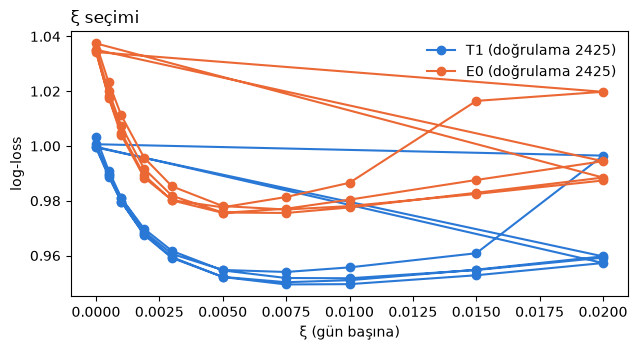

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (lg, res), c in zip(results.items(), ["#2a78d6", "#eb6834"]):
    t = res.xi_table
    ax.plot(t.xi, t.log_loss, "o-", color=c, label=f"{lg} (doğrulama {res.seasons[1]})", ms=6)
ax.set_xlabel("ξ (gün başına)"); ax.set_ylabel("log-loss"); ax.set_title("ξ seçimi", loc="left"); ax.legend(frameon=False)
plt.tight_layout()

Her iki ligde de doğrulama log-loss'u iç bir ξ değerinde minimuma iniyor. T1 verisi eksiksiz hale gelmeden önce (2021-23 boşluğu) büyük ξ'lerde eğri bozuluyordu.

In [8]:
for lg, res in results.items():
    p = res.predictions
    d, se = paired_logloss_diff(p[["dc_H","dc_D","dc_A"]].to_numpy(), p[["po_H","po_D","po_A"]].to_numpy(), p.y.to_numpy())
    print(f"{lg}: Dixon-Coles − Poisson log-loss = {d:+.4f}  (95% GA {d-1.96*se:+.4f} … {d+1.96*se:+.4f})")

T1: Dixon-Coles − Poisson log-loss = -0.0055  (95% GA -0.0176 … +0.0066)
E0: Dixon-Coles − Poisson log-loss = +0.0003  (95% GA -0.0058 … +0.0063)


## 5. Kalibrasyon

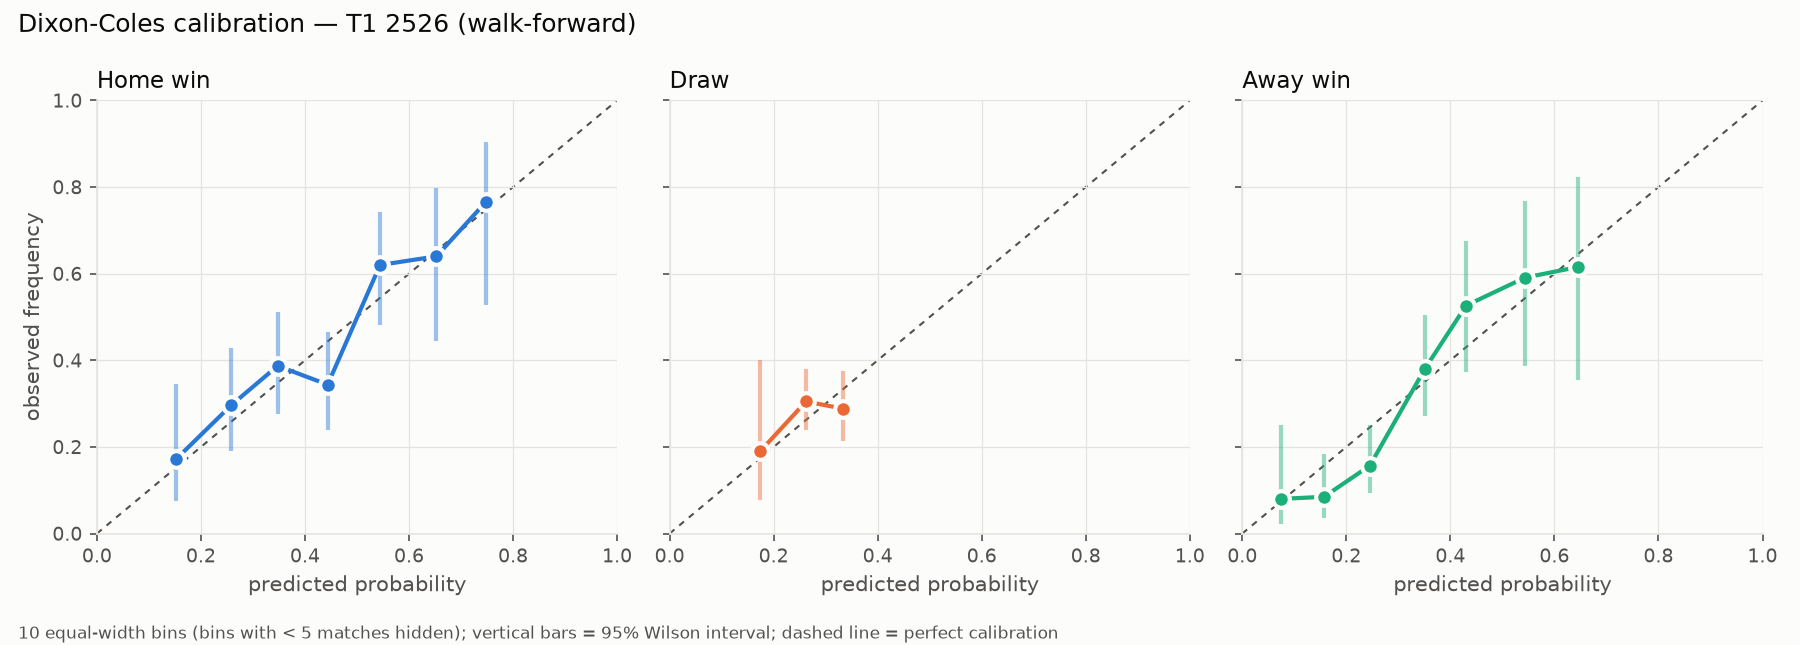

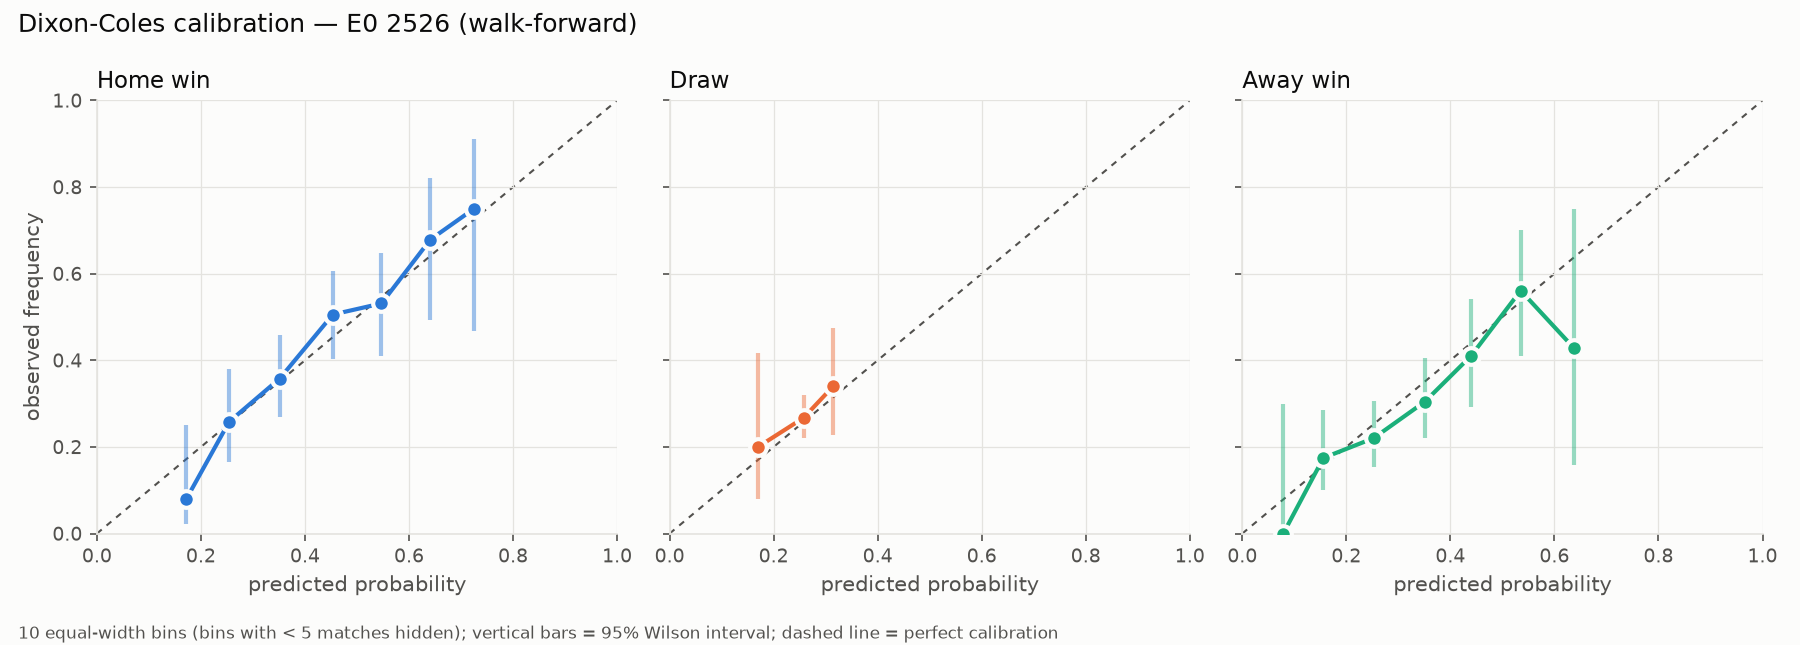

In [9]:
from IPython.display import Image, display
for lg in leagues:
    display(Image(f"../docs/img/calibration_{lg}.png"))

## 6. Sonuç

* Model sınıf frekanslarına göre belirgin biçimde daha iyi (log-loss ve RPS).
* Dixon-Coles düzeltmesinin düz Poisson'a göre katkısı bu test sezonlarında istatistiksel olarak ayırt edilemiyor (güven aralığı 0'ı içeriyor).
* Bahis piyasası ile karşılaştırma yapılamadı: kullanılan openfootball verisi oran içermiyor. football-data.co.uk kaynağıyla (`--source football-data`) bu karşılaştırma otomatik eklenir.

## 7. Ligler arası model: tüm ligler + Avrupa kupaları

Takım gücü = lig seviyesi + takımın ligine göre sapması. Ligleri birbirine yalnızca UEFA kulüp maçları bağlar. Ayarlar 2024-25 Avrupa maçlarında seçildi (`BEST_PARAMS`); aşağıdaki test 2025-26 Avrupa maçlarında, zaman sıralı.

In [10]:
from football_predictor.multileague import load_world, CrossLeagueModel, BEST_PARAMS, walk_forward_uefa
from football_predictor.evaluate import all_metrics, frequency_probs
world = load_world("../data")
wm = CrossLeagueModel(**BEST_PARAMS).fit(world, ref_date=pd.Timestamp("2026-10-15"))
print(f"{len(world)} maç, {len(wm.teams)} takım, {len(wm.leagues)} lig grubu; parametreler: {BEST_PARAMS}")
wm.league_table(world).head(15)

31560 maç, 875 takım, 32 lig grubu; parametreler: {'xi': 0.0005, 'l2_team': 10.0, 'l2_league': 0.1}


,league,name,attack,defence,strength,home_adv,uefa_matches
0,GB1,England,0.5589,-0.4947,1.0537e+00,0.1900,433
1,ES1,Spain,0.3290,-0.4080,7.3697e-01,0.2702,398
2,L1,Germany,0.3733,-0.2712,6.4452e-01,0.2317,378
3,IT1,Italy,0.2807,-0.3138,5.9455e-01,0.1425,404
4,FR1,France,0.3047,-0.2591,5.6386e-01,0.1905,332
5,PO1,Portugal,0.0195,-0.1108,1.3022e-01,0.2224,274
6,NL1,Netherlands,0.0928,-0.0260,1.1881e-01,0.2389,303
7,DK1,Denmark,0.1068,0.0114,9.5398e-02,0.1345,196
8,BE1,Belgium,0.0400,-0.0175,5.7486e-02,0.2187,268
9,PL1,Poland,0.0110,-0.0267,3.7743e-02,0.2788,194


In [11]:
tt = wm.team_table()
tt["dünya sırası"] = range(1, len(tt) + 1)
tt[tt.league == "TR1"][["dünya sırası", "team", "attack", "defence", "strength"]].head(10)

,dünya sırası,team,attack,defence,strength
65,66,Galatasaray,0.4676,-0.3198,0.7874
73,74,Fenerbahçe,0.5049,-0.2498,0.7547
178,179,Beşiktaş,0.2015,-0.1348,0.3363
182,183,Trabzonspor,0.2413,-0.0918,0.3331
191,192,İstanbul Başakşehir,0.1500,-0.1650,0.3150
277,278,Samsunspor,0.0029,-0.1083,0.1112
311,312,Amed,0.0673,0.0253,0.0421
340,341,Göztepe,0.0173,0.0245,-0.0071
362,363,Alanyaspor,-0.0059,0.0217,-0.0276
385,386,Konyaspor,-0.0673,-0.0113,-0.0560


In [12]:
test = world.is_uefa & (world.Date >= "2025-07-01") & (world.Date < "2026-07-01")
h = walk_forward_uefa(world, test, **BEST_PARAMS)
po = walk_forward_uefa(world, test, xi=BEST_PARAMS["xi"], l2_team=2.0, hierarchical=False)
y = h.y.to_numpy()
past = world[world.is_uefa & (world.Date < "2025-07-01")]
pd.DataFrame([{"model": "Sınıf frekansları", **all_metrics(frequency_probs(past, len(y)), y)},
              {"model": "Tek havuz (lig katmanı yok)", **all_metrics(po[["pH","pD","pA"]].to_numpy(), y)},
              {"model": "Ligler arası hiyerarşik", **all_metrics(h[["pH","pD","pA"]].to_numpy(), y)}])

,model,n,log_loss,rps,brier,accuracy
0,Sınıf frekansları,959,1.0311,0.2344,0.6223,0.4880
1,Tek havuz (lig katmanı yok),959,0.9555,0.2058,0.5657,0.5547
2,Ligler arası hiyerarşik,959,0.9474,0.2038,0.5602,0.5620


In [13]:
d, se = paired_logloss_diff(h[["pH","pD","pA"]].to_numpy(), po[["pH","pD","pA"]].to_numpy(), y)
print(f"Hiyerarşik − tek havuz log-loss: {d:+.4f}  (95% GA {d-1.96*se:+.4f} … {d+1.96*se:+.4f})")

Hiyerarşik − tek havuz log-loss: -0.0080  (95% GA -0.0167 … +0.0007)


### Canlı test: KuPS - Trabzonspor (15 Ekim 2026)

Tahmin maçtan önce `outputs/prediction_kups_trabzonspor_2026-10-15.json` dosyasına kaydedildi. Aşağıdaki hücre aynı tahmini yalnızca 15 Ekim 2026 öncesi verilerle yeniden üretir. Sonuç belli olunca puanlamak için:
`football-predictor score-prediction outputs/prediction_kups_trabzonspor_2026-10-15.json --result <KuPS>-<Trabzonspor>`

Beklenen gol 1.00 - 1.54;  KuPS / X / Trabzonspor = 24.2% / 26.5% / 49.3%


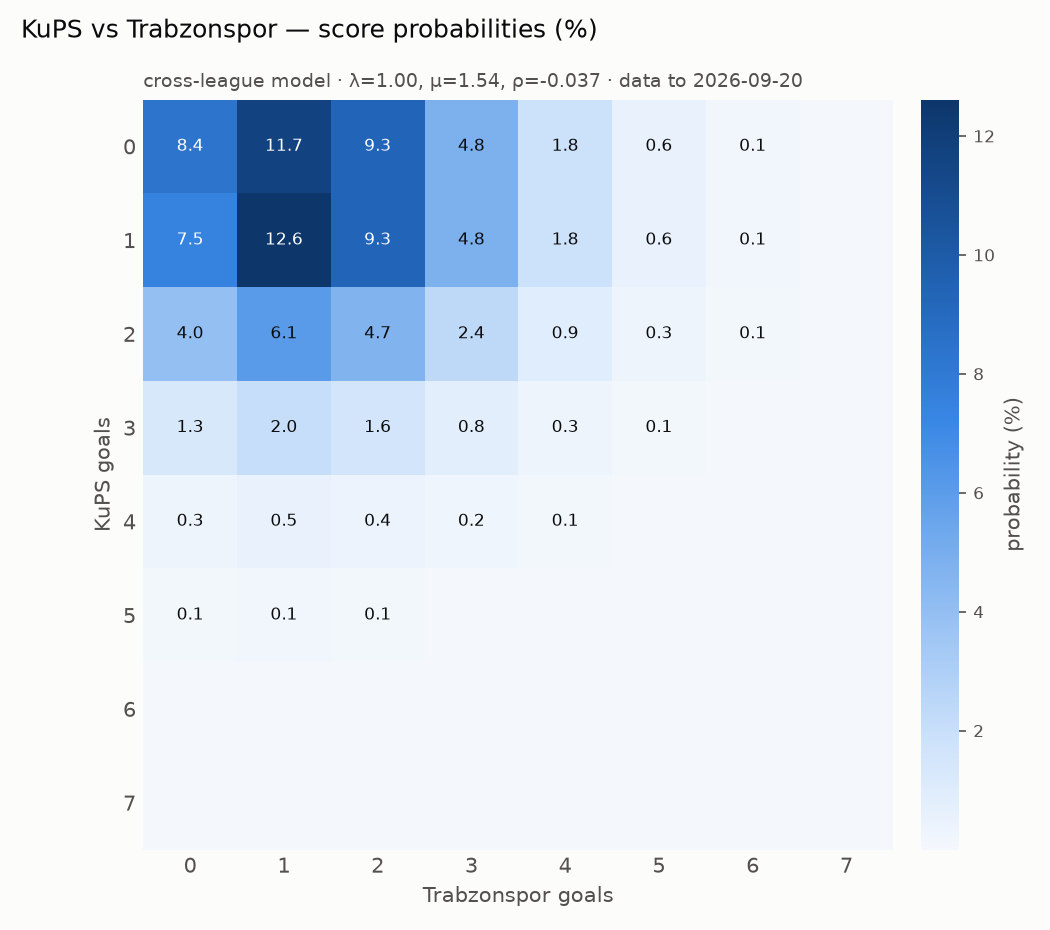

In [14]:
from football_predictor.model import outcome_probs
lam, mu, M = wm.predict_matrix("6251", "449", "UEFA")   # KuPS (ev), Trabzonspor
print(f"Beklenen gol {lam:.2f} - {mu:.2f};  KuPS / X / Trabzonspor = " + " / ".join(f"{100*v:.1f}%" for v in outcome_probs(M)))
display(Image("../docs/img/heatmap_kups_trabzonspor.png"))